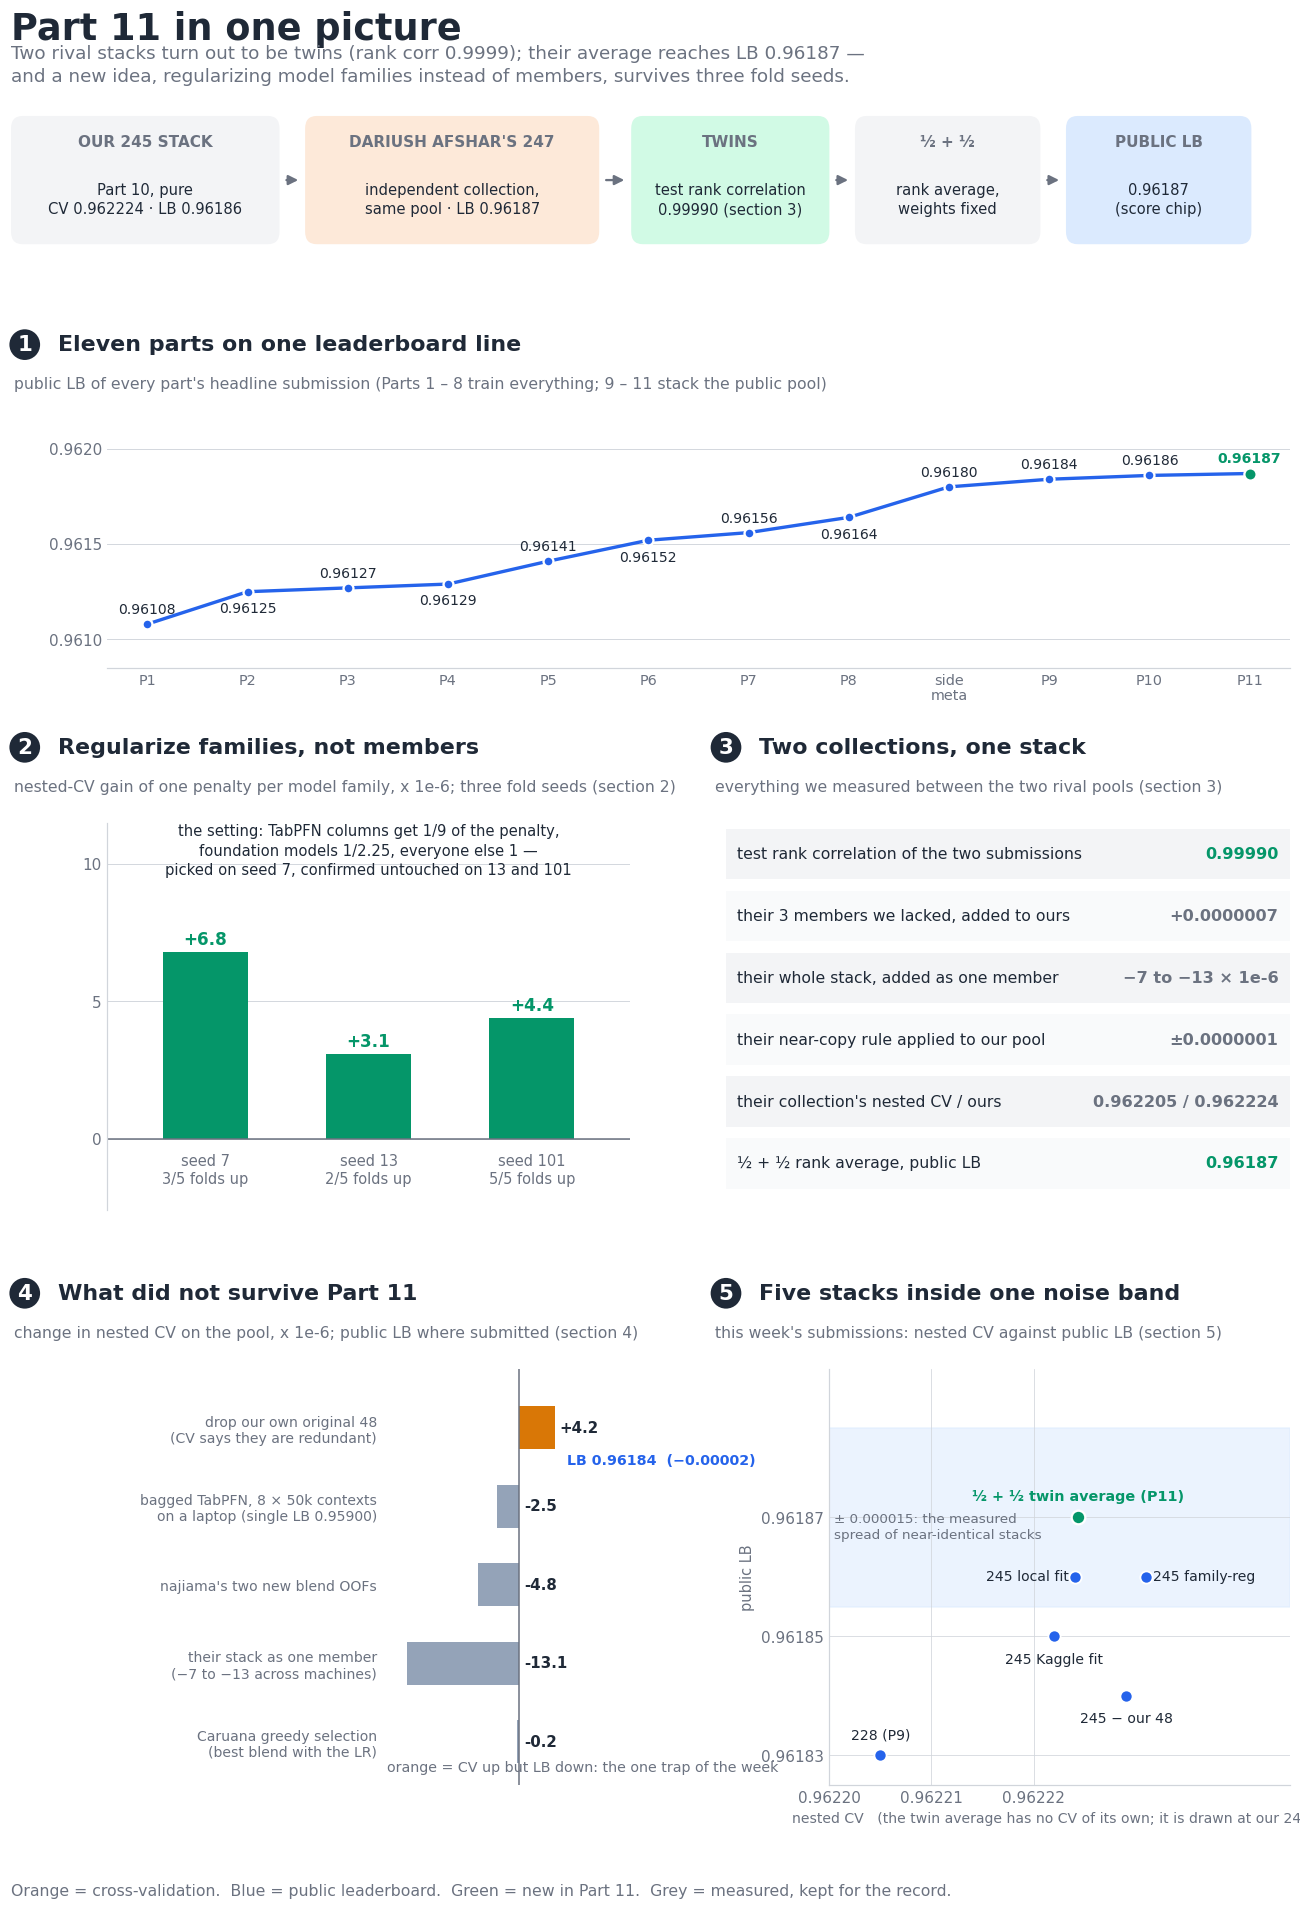

In [1]:
# Part 11 in one picture.  Every number is from our local runs (nested CV, meta folds
# StratifiedKFold(5, shuffle=True, random_state=7/13/101)) or from the public leaderboard; each panel
# names the section that derives it.  Nothing is computed by this cell.
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Rectangle

INK, MUTED, RULE, CARD = "#1f2937", "#6b7280", "#d1d5db", "#f3f4f6"
CV, LB, NEW, BAD = "#d97706", "#2563eb", "#059669", "#94a3b8"   # cross-validation / leaderboard / new in Part 11 / kept for the record
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11, "text.color": INK,
                     "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED})
fig = plt.figure(figsize=(12.5, 17.6), dpi=110, facecolor="white")
fig.text(0.04, 0.982, "Part 11 in one picture", fontsize=24, fontweight="bold", va="center")
fig.text(0.04, 0.9635, "Two rival stacks turn out to be twins (rank corr 0.9999); their average reaches LB 0.96187 —\n"
                       "and a new idea, regularizing model families instead of members, survives three fold seeds.",
         fontsize=12, color=MUTED, va="center", linespacing=1.35)

# ---------------------------------------------------------------- the pipeline
ax = fig.add_axes([0.04, 0.868, 0.93, 0.072]); ax.set_xlim(0, 100); ax.set_ylim(0, 10); ax.axis("off")
boxes = [(0.0, 21.0, "OUR 245 STACK", "Part 10, pure\nCV 0.962224 · LB 0.96186", CARD),
         (23.0, 23.0, "DARIUSH AFSHAR'S 247", "independent collection,\nsame pool · LB 0.96187", "#fde9d9"),
         (48.5, 15.5, "TWINS", "test rank correlation\n0.99990 (section 3)", "#d1fae5"),
         (66.0, 14.5, "½ + ½", "rank average,\nweights fixed", CARD),
         (82.5, 14.5, "PUBLIC LB", "0.96187\n(score chip)", "#dbeafe")]
for x, w, head, body, col in boxes:
    ax.add_patch(FancyBboxPatch((x, 0.4), w, 9.2, boxstyle="round,pad=0,rounding_size=0.9", fc=col, ec="none"))
    ax.text(x + w / 2, 7.7, head, ha="center", va="center", fontsize=10, fontweight="bold", color=MUTED)
    ax.text(x + w / 2, 3.6, body, ha="center", va="center", fontsize=9.7, linespacing=1.4)
for (x, w, *_), (x2, *_) in zip(boxes[:-1], boxes[1:]):
    ax.add_patch(FancyArrowPatch((x + w + 0.3, 5), (x2 - 0.3, 5), arrowstyle="-|>", mutation_scale=13, color=MUTED, lw=1.5))


def panel(x, y, w, h, pad, no, title, sub):
    fig.text(x, y + h + 0.039, f"{no}", fontsize=14, fontweight="bold", color="white", va="center", ha="center",
             bbox=dict(boxstyle="circle,pad=0.25", fc=INK, ec="none"))
    fig.text(x + 0.024, y + h + 0.039, title, fontsize=14.5, fontweight="bold", va="center")
    fig.text(x - 0.008, y + h + 0.0185, sub, fontsize=10.2, color=MUTED, va="center")
    a = fig.add_axes([x + pad, y, w - pad, h])
    for s in ("top", "right"):
        a.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        a.spines[s].set_color(RULE)
    a.tick_params(length=0, labelsize=10)
    return a


# ---------------------------------------------------------------- 1. eleven parts on one line
a = panel(0.05, 0.652, 0.92, 0.128, 0.06, 1, "Eleven parts on one leaderboard line",
          "public LB of every part's headline submission (Parts 1 – 8 train everything; 9 – 11 stack the public pool)")
parts = [("P1", 0.96108), ("P2", 0.96125), ("P3", 0.96127), ("P4", 0.96129), ("P5", 0.96141), ("P6", 0.96152),
         ("P7", 0.96156), ("P8", 0.96164), ("side\nmeta", 0.96180), ("P9", 0.96184), ("P10", 0.96186), ("P11", 0.96187)]
xs = range(len(parts))
a.plot(list(xs), [v for _, v in parts], color=LB, lw=2.2, zorder=2)
for i, (lab, v) in enumerate(parts):
    col = NEW if lab == "P11" else LB
    a.scatter([i], [v], s=64 if col == NEW else 42, color=col, zorder=3, edgecolor="white", linewidth=1.5)
    a.text(i, v + 0.000055 if i % 2 == 0 or i > 7 else v - 0.00011, f"{v:.5f}", ha="center", fontsize=9.2,
           color=NEW if col == NEW else INK, fontweight="bold" if col == NEW else "normal")
a.set_xticks(list(xs)); a.set_xticklabels([p for p, _ in parts], fontsize=9.4, linespacing=1.1)
a.set_ylim(0.96085, 0.96215); a.set_yticks([0.9610, 0.9615, 0.9620]); a.set_xlim(-0.4, len(parts) - 0.6)
a.grid(axis="y", color=RULE, lw=0.6); a.set_axisbelow(True); a.spines["left"].set_visible(False)

# ---------------------------------------------------------------- 2. family regularization
a = panel(0.05, 0.372, 0.44, 0.2, 0.06, 2, "Regularize families, not members",
          "nested-CV gain of one penalty per model family, x 1e-6; three fold seeds (section 2)")
seeds = ["seed 7", "seed 13", "seed 101"]
gains = [6.8, 3.1, 4.4]
folds = ["3/5", "2/5", "5/5"]
for i, (sd, g, fo) in enumerate(zip(seeds, gains, folds)):
    a.bar(i, g, width=0.52, color=NEW)
    a.text(i, g + 0.25, f"+{g}", ha="center", fontsize=11, fontweight="bold", color=NEW)
    a.text(i, -0.55, f"{sd}\n{fo} folds up", ha="center", va="top", fontsize=9.6, color=MUTED, linespacing=1.25)
a.axhline(0, color=MUTED, lw=1)
a.text(1.0, 9.6, "the setting: TabPFN columns get 1/9 of the penalty,\nfoundation models 1/2.25, everyone else 1 —\n"
                 "picked on seed 7, confirmed untouched on 13 and 101",
       ha="center", fontsize=9.7, color=INK, linespacing=1.4)
a.set_xlim(-0.6, 2.6); a.set_ylim(-2.6, 11.5); a.set_xticks([]); a.set_yticks([0, 5, 10])
a.grid(axis="y", color=RULE, lw=0.6); a.set_axisbelow(True); a.spines["bottom"].set_visible(False)

# ---------------------------------------------------------------- 3. the twins
a = panel(0.56, 0.372, 0.41, 0.2, 0.0, 3, "Two collections, one stack",
          "everything we measured between the two rival pools (section 3)")
a.axis("off"); a.set_xlim(0, 100); a.set_ylim(0, 100)
rows = [("test rank correlation of the two submissions", "0.99990"),
        ("their 3 members we lacked, added to ours", "+0.0000007"),
        ("their whole stack, added as one member", "−7 to −13 × 1e-6"),
        ("their near-copy rule applied to our pool", "±0.0000001"),
        ("their collection's nested CV / ours", "0.962205 / 0.962224"),
        ("½ + ½ rank average, public LB", "0.96187")]
for i, (k, v) in enumerate(rows):
    yy = 92 - i * 16
    a.add_patch(Rectangle((0, yy - 6.5), 100, 13, fc="#f9fafb" if i % 2 else CARD, ec="none"))
    a.text(2, yy, k, fontsize=10.2, va="center", color=INK)
    a.text(98, yy, v, fontsize=10.6, va="center", ha="right", fontweight="bold",
           color=NEW if i in (0, 5) else MUTED)

# ---------------------------------------------------------------- 4. what did not survive
a = panel(0.05, 0.075, 0.44, 0.215, 0.26, 4, "What did not survive Part 11",
          "change in nested CV on the pool, x 1e-6; public LB where submitted (section 4)")
bad = [("drop our own original 48\n(CV says they are redundant)", 4.2, "LB 0.96184  (−0.00002)"),
       ("bagged TabPFN, 8 × 50k contexts\non a laptop (single LB 0.95900)", -2.5, ""),
       ("najiama's two new blend OOFs", -4.8, ""),
       ("their stack as one member\n(−7 to −13 across machines)", -13.1, ""),
       ("Caruana greedy selection\n(best blend with the LR)", -0.2, "")]
for i, (lab, v, note) in enumerate(bad):
    col = CV if v > 0 else BAD
    a.barh(i, v, height=0.55, color=col)
    a.text(v + 0.6 if v > 0 else 0.6, i, f"{v:+.1f}", va="center", ha="left",
           fontsize=9.8, color=INK, fontweight="bold")
    if note:
        a.text(5.6, i + 0.42, note, fontsize=9.3, color=LB, fontweight="bold", va="center")
a.axvline(0, color=MUTED, lw=1)
a.set_yticks(range(len(bad))); a.set_yticklabels([b[0] for b in bad], fontsize=9.2, linespacing=1.2)
a.set_ylim(len(bad) - 0.45, -0.75); a.set_xlim(-16, 13); a.set_xticks([])
a.spines["bottom"].set_visible(False); a.spines["left"].set_visible(False)
a.text(-15.5, 4.38, "orange = CV up but LB down: the one trap of the week", fontsize=9.3, color=MUTED, ha="left")

# ---------------------------------------------------------------- 5. the noise band
a = panel(0.56, 0.075, 0.41, 0.215, 0.075, 5, "Five stacks inside one noise band",
          "this week's submissions: nested CV against public LB (section 5)")
pts = [("228 (P9)", 0.962205, 0.96183), ("245 local fit", 0.962224, 0.96186), ("245 Kaggle fit", 0.962222, 0.96185),
       ("245 − our 48", 0.962229, 0.96184), ("245 family-reg", 0.962231, 0.96186)]
a.axhspan(0.961855, 0.961885, color="#dbeafe", alpha=0.55, zorder=0)
a.text(0.9622005, 0.9618665, "± 0.000015: the measured\nspread of near-identical stacks",
       fontsize=8.8, color=MUTED, linespacing=1.3)
offs = {"228 (P9)": (0, 0.0000028, "center"), "245 local fit": (-0.0000006, 0, "right"),
        "245 Kaggle fit": (0, -0.0000045, "center"), "245 − our 48": (0, -0.0000045, "center"),
        "245 family-reg": (0.0000006, 0, "left")}
for lab, c, l in pts:
    a.scatter([c], [l], s=64, color=LB, zorder=3, edgecolor="white", linewidth=1.2)
    dx, dy, ha = offs[lab]
    a.text(c + dx, l + dy, lab, fontsize=9.2, ha=ha, va="center" if dy == 0 else "baseline", color=INK)
a.scatter([0.9622243], [0.96187], s=80, color=NEW, zorder=4, edgecolor="white", linewidth=1.5)
a.text(0.9622243, 0.96187 + 0.0000028, "½ + ½ twin average (P11)", fontsize=9.4, ha="center", color=NEW, fontweight="bold")
a.set_xlim(0.9622, 0.962245); a.set_ylim(0.961825, 0.961895)
a.set_xticks([0.96220, 0.96221, 0.96222]); a.set_xticklabels(["0.96220", "0.96221", "0.96222"])
a.set_yticks([0.96183, 0.96185, 0.96187]); a.set_yticklabels(["0.96183", "0.96185", "0.96187"])
a.set_xlabel("nested CV   (the twin average has no CV of its own; it is drawn at our 245's)", fontsize=9.2)
a.set_ylabel("public LB", fontsize=9.6)
a.grid(color=RULE, lw=0.5); a.set_axisbelow(True)

fig.text(0.04, 0.02, "Orange = cross-validation.  Blue = public leaderboard.  Green = new in Part 11.  Grey = measured, kept for the record.",
         fontsize=10.3, color=MUTED, va="center")
fig.savefig("part11_summary.png", facecolor="white")
plt.show()

# S6E10 | Twin Stacks + Family Reg | LB 0.96187

> 📦 **The dataset behind this series:** [s6e10-goodpjw2008-extra-members-oof](https://www.kaggle.com/datasets/goodpjw2008/s6e10-goodpjw2008-extra-members-oof) —
> the 17 members and the frozen 245 stack that Dariush Afshar's and ewtherka's stacks also build on,
> each file with a model card. If you use it, an upvote **on the dataset** helps the most.

> **Part 11 of a series, published as a new version of the same notebook.** [Part 1 (LB 0.96108)](https://www.kaggle.com/code/goodpjw2008/s6e10-route-id-fe-og-model-stack-lb-0-96108) ·
> [Part 2 (0.96125)](https://www.kaggle.com/code/goodpjw2008/s6e10-two-view-gbdt-realmlp-stack-lb-0-96125) ·
> [Part 3 (0.96127)](https://www.kaggle.com/code/goodpjw2008/s6e10-catboost-ctr-glm-margin-xgb-lb-0-96127) ·
> [Part 4 (0.96129)](https://www.kaggle.com/code/goodpjw2008/s6e10-auxiliary-task-features-lb-0-96129) ·
> [Part 5 (0.96141)](https://www.kaggle.com/code/goodpjw2008/s6e10-realmlp-aux-task-features-lb-0-96141) ·
> [Part 6 (0.96152)](https://www.kaggle.com/code/goodpjw2008/s6e10-more-aux-carriers-lb-0-96152) ·
> [Part 7 (0.96156)](https://www.kaggle.com/code/goodpjw2008/s6e10-tabpfn-3-5-member-lb-0-96156) ·
> [Part 8 (0.96160 → 0.96164)](https://www.kaggle.com/code/goodpjw2008/s6e10-228-member-meta-stack-lb-0-96184?scriptVersionId=355094993), all 48 models' training code ·
> [side episode (0.96180)](https://www.kaggle.com/code/goodpjw2008/s6e10-meta-stack-on-public-oof-lb-0-96180) ·
> Part 9 (0.96184) and Part 10 (0.96186): earlier versions of this page (Version menu).

**What you just saw.** Part 10 ended with a pure 245-member stack at LB 0.96186 and a claim: the public
pool has converged, and the last leaderboard point separating the top restacks is noise. The same day,
[Dariush Afshar published his own collection of the whole pool](https://www.kaggle.com/code/dariushafshar/s6e10-247-public-oofs-one-stack-lb-0-96187) — built independently, with his
own checks — and scored 0.96187. Part 11 is what happened when the two collections met, plus one new
method and one widely-useful warning:

1. **The twins measurement (section 3).** His 247 and our 245 contain almost exactly the same
   information: our test predictions rank-correlate at **0.99990**. His three members we lacked add
   +0.0000007 to our stack; his whole stack, added as a member, *loses* 7 – 13 × 1e-6 (machine-dependent, always negative); his near-copy rule
   changes ours by ±0.0000001. Two collectors, two codebases, one stack. The ½ + ½ rank average of the
   two — weights fixed in advance, nothing tuned — scores **public LB 0.96187**, the file this notebook
   submits. Half of it is his; that is stated here and in the credits, and the average did **not** beat
   both parents, which is itself the cleanest evidence the remaining disagreement is noise.
2. **Regularize families, not members (section 2).** A new stacker twist we have not seen published for
   this competition: give each model *family* its own L2 penalty (TabPFN columns 1/9 of the default,
   foundation models 1/2.25). Picked on one fold seed, it survives two untouched seeds (+0.0000031 and
   +0.0000044, 5/5 folds on the second) — our best remaining CV, 0.962231.
3. **One trap worth your submissions (section 4).** Nested CV says our own original 48 members are now
   redundant (+0.0000042 when removed, 4/5 folds). The public LB disagrees: −0.00002. CV earns trust at
   the *pool* level; structural deletions still need an LB check.

**Scores, stated exactly.** Our pure 245 stack: LB **0.96186** (Part 10). This notebook's submission,
the ½ + ½ twin average: LB **0.96187** — it *ties* the best public score, carried half by
[Dariush Afshar's work](https://www.kaggle.com/code/dariushafshar/s6e10-247-public-oofs-one-stack-lb-0-96187); upvote him first. Both halves load from frozen published files, so this
page's score chip reproduces 0.96187 exactly on every re-run.

> **What you can take from this page**
> - **The family-regularization recipe** (section 2): five lines on top of any logistic stack, with the
>   three-seed validation discipline that keeps you from fooling yourself.
> - **A loader for the full public pool** (section 1, from Part 10) and the twin-stack audit kit (section 3).
> - **A laptop TabPFN recipe** (section 4): 8 × 50k bagged contexts on Apple MPS, single-model LB 0.95900 —
>   including why it still failed as a stack member.


## Scoreboard: Part 10 → Part 11

Nested CV = the combiner is scored only on rows its weights never saw (meta folds seed 7 unless stated;
members use seed 42). The Parts 1 – 8 technique tables live in [version 1 of this page](https://www.kaggle.com/code/goodpjw2008/s6e10-228-member-meta-stack-lb-0-96184?scriptVersionId=355094993).

| stack | nested CV | public LB |
|---|---|---|
| Part 10: our 245, LR C = 0.003, pure | 0.962224 | **0.96186** |
| **+ family-wise regularization** *(new)* | **0.962231** (seed 7; +3.1 / +4.4 × 1e-6 on seeds 13 / 101) | 0.96186 |
| [Dariush Afshar's 247](https://www.kaggle.com/code/dariushafshar/s6e10-247-public-oofs-one-stack-lb-0-96187), his run | 0.962205 (his folds) | 0.96187 |
| **½ our 245 + ½ his 247, rank average** *(new, this notebook's file)* | — (no honest CV: parents share every member) | **0.96187** |

### Submission history (every file, CV vs public LB)

| # | date | what | CV | LB |
|---|---|---|---|---|
| 1 – 19 | 10-01 → 10-04 | Parts 1 – 8 (own models only, 48 by the end) | 0.958763 → 0.961935 | 0.95808 → 0.96160 (Kaggle run 0.96164) |
| 23 | 10-08 | side episode, 182 public members | 0.962110 | 0.96180 |
| 25 – 26 | 10-11 | Part 9: + 29 public, + 17 of ours | 0.962182 / 0.962205 | 0.96181 / 0.96183 |
| 29 | 10-12 | Part 10: + kagankoral's 17, pure 245 | 0.962222 | **0.96186** (Kaggle-fit output: 0.96185) |
| 33 | 10-12 | *measurement:* 245 minus our own 48 | 0.962229 (+4.2 × 1e-6!) | 0.96184 — **CV up, LB down** |
| 34 | 10-12 | *measurement:* bagged laptop TabPFN, single model | OOF 0.95978 | 0.95900 |
| 35 | 10-12 | *measurement:* ½ ours + ½ Dariush Afshar's | — | **0.96187** (this notebook's file) |
| 36 | 10-12 | family-wise regularization | 0.962231 | 0.96186 |

CV − LB has stayed between 0.00028 and 0.00038 since Part 1. Within this week's stacks the public LB
spans 0.96184 – 0.96187 while nested CV spans 0.000026 — consistent with the ±0.000015 spread
[a public notebook measured](https://www.kaggle.com/competitions/playground-series-s6e10/discussion/747982)
for near-identical predictions. We pick by CV and report every LB reading.


## Credits and thanks

**The headline credit of this part: [Dariush Afshar](https://www.kaggle.com/code/dariushafshar/s6e10-247-public-oofs-one-stack-lb-0-96187).** His independent collection of the whole
public pool (247 pairs, his own pre-registered checks), his published nested stack pair
(`stack_oof.npy` / `stack_test.npy`), and his `submission.csv` — which is **half of this notebook's
final file**. He also published the [golem OOF library](https://www.kaggle.com/datasets/dariushafshar/s6e10-golem-oof-library)
and the label-noise analysis this series has cited since Part 9. If you upvote one page today, make it his.

**The 245 members themselves** are credited source by source in Part 10 (the previous version of this
page): Chris Deotte's two packaged datasets (124 + 11, with kratosyan's collection inside, our 48 among
them), kagankoral's 22, sadamtorres' 38, abdullahsafwan333's 5, koumeimaki's 7, sachith7's 24,
dariushafshar's 17, amanatar's 11, megayak, busyaprime, mitudru, arhancanli12, thisray, samanyu1808,
hemingweb, wangxintong111, najiama, yekenot, hermengardo, kratosyan, dmitriykolmikov, kozykappa —
and [our own 17-member dataset](https://www.kaggle.com/datasets/goodpjw2008/s6e10-goodpjw2008-extra-members-oof),
which now also carries the frozen 245-stack pair this notebook loads.

**Tested for this part, excluded with the numbers shown (section 4):** najiama's two new blend OOFs,
kozykappa's source-transfer LightGBM, sadamtorres' two original-data models, mojjeed's 15-fold GBDTs,
ewtherka's factorization machine, irynavs' CPU baseline — thank you all for publishing; a negative
reading is still a reading.

**Ideas we borrowed, with thanks:** yeashusemwal (LR C = 0.003, meta folds on a different seed),
Chris Deotte (logit conventions), karttikjangid05 (the test-half row-order check),
[Hitarth Jain](https://www.kaggle.com/competitions/playground-series-s6e10/discussion/747982) (the LB-noise yardstick),
[Koumei Maki](https://www.kaggle.com/competitions/playground-series-s6e10/discussion/747823) (the residual-feature leakage warning).

**What is ours:** Parts 1 – 10, the family-regularization method and its three-seed validation, the
twin-stack audit of section 3, the laptop-TabPFN recipe and its honest failure, and every measurement here.


## 1. The 245 members (Part 10's pool, loaders unchanged)

In [2]:
import glob, json, os, time, warnings
import numpy as np, pandas as pd
from joblib import Parallel, delayed
from scipy.stats import rankdata, spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
warnings.filterwarnings("ignore")

INPUT = os.environ.get("INPUT_DIR", "/kaggle/input")
def find(pat, hint):
    hits = sorted(p for p in glob.glob(f"{INPUT}/**/{pat}", recursive=True) if hint in p)
    assert hits, (pat, hint)
    return hits

tr = pd.read_csv(find("train.csv", "playground-series-s6e10")[0])
te = pd.read_csv(find("test.csv", "playground-series-s6e10")[0])
y = tr["satisfaction"].astype(int).values

def logit(p):
    p = np.clip(np.asarray(p, dtype=np.float64), 1e-15, 1 - 1e-15)
    return np.clip(np.log(p / (1 - p)), -30, 30)
def tologit(v):
    v = np.asarray(v, dtype=np.float64)
    return v if (v.min() < 0 or v.max() > 1) else logit(v)

names, cols, tcols = [], [], []
def add(name, o, t):
    o, t = np.asarray(o).ravel(), np.asarray(t).ravel()
    assert len(o) == len(y) and len(t) == len(te) and not np.isnan(o).any(), name
    names.append(name); cols.append(tologit(o)); tcols.append(tologit(t))

def by_id(path, ids, col):
    return pd.read_csv(path).set_index("id").loc[ids, col].values

# ---- the 245 members of Part 10 (the loaders are unchanged; see that version for the commentary)
for d, tag in ((find("oof_gp_cat_ctr.npy", "124-public")[0], ""), (find("oof_tabfm.npy", "tfm-oof")[0], "tfm_")):
    d = os.path.dirname(d)
    for f in sorted(glob.glob(f"{d}/oof_*.npy")):
        add(tag + os.path.basename(f)[4:-4], np.load(f), np.load(f.replace("oof_", "test_")))
d = os.path.dirname(find("oof_o_tabpfn35.npy", "golem")[0])
for n in ("o_tabpfn35", "p_lgbm_auxev", "q_lgbm_auxev_10fold"):
    add("gl2_" + n, np.load(f"{d}/oof_{n}.npy"), np.load(f"{d}/test_{n}.npy"))
d = os.path.dirname(find("preds_e1_allcat_cat.npz", "artifacts")[0])
for f in sorted(glob.glob(f"{d}/preds_*.npz")) + sorted(glob.glob(f"{d}/orig_*_pred.npz")):
    z = np.load(f)
    if "oof" in z and "test" in z and len(z["oof"]) == len(y) and not np.isnan(z["oof"]).any():
        add("st_" + os.path.basename(f)[:-4].replace("preds_", ""), z["oof"], z["test"])
d = os.path.dirname(find("oof_forge_cat.npy", "forge")[0])
for f in sorted(glob.glob(f"{d}/oof_forge_*.npy")):
    add("am_" + os.path.basename(f)[4:-4], np.load(f), np.load(f.replace("oof_", "test_")))
d = os.path.dirname(find("tabpfn_catfd10_oof.csv", "oof-dataset")[0])
for m in ("cat_v3", "tabpfn_catfd10", "tabpfn_raw", "tabpfn_te_cnt", "xgb_v3"):
    add("ab_" + m, by_id(f"{d}/{m}_oof.csv", tr["id"], "pred"), by_id(f"{d}/{m}_test.csv", te["id"], "pred"))
d = os.path.dirname(find("train_ids_folds.csv", "route-tfm-nn-oof")[0])
for m in ("cat_w1", "lgb_w1", "rmlp_f_nc", "tabicl_fdcat_c250k", "tabm_bcd_rc_v2", "tabpfn_catfd10", "xgb_w1"):
    add("km_" + m, np.load(f"{d}/oof_{m}.npy"), np.load(f"{d}/test_{m}.npy"))
d = os.path.dirname(find("lgb_cpu_strong.npz", "stack-oof-predictions")[0])
for m in ("lgb_cpu_strong", "xgb_A_auxall"):
    z = np.load(f"{d}/{m}.npz"); add("s7_" + m, z["oof"], z["test"])
for m in ("rmlp_route_ogaux", "xgb_route_ogaux"):
    z = np.load(find(f"{m}.npz", "route-id-teacher")[0]); add("kr_" + m, z["oof"], z["test"])
d = os.path.dirname(find("oof_members.csv", "encodings-catboost-realmlp")[0])
for m in ("lgb", "xgb", "cat", "cat_allcat", "realmlp"):
    add("kg_" + m, by_id(f"{d}/oof_members.csv", tr["id"], m), by_id(f"{d}/test_members.csv", te["id"], m))
d = os.path.dirname(find("oof_preds.csv", "realmlp-pytabkit")[0])
add("yk_realmlp", by_id(f"{d}/oof_preds.csv", tr["id"], "satisfaction"), by_id(f"{d}/submission.csv", te["id"], "satisfaction"))
d = os.path.dirname(find("oof_train.npy", "single-catboost-eda")[0])
add("hm_cat", np.load(f"{d}/oof_train.npy"), np.load(f"{d}/oof_test.npy"))
d = os.path.dirname(find("oof_cb_cat.npy", "catboost-all-categorical")[0])
add("dk_cbcat", np.load(f"{d}/oof_cb_cat.npy"), np.load(f"{d}/test_cb_cat.npy"))
z = np.load(find("oof_artifacts.npz", "original-prior-stack-v5")[0])
for m in ("lgbm_champion", "lgbm_te", "lgbm_te_rows", "xgb_gpu", "catboost_gpu"):
    add("av5_" + m, z["oof_" + m], z["test_" + m])
d = os.path.dirname(find("members.csv", "goodpjw2008-extra-members")[0])
for m in pd.read_csv(f"{d}/members.csv")["member"]:
    add("gpx_" + m, np.load(f"{d}/oof_{m}.npy"), np.load(f"{d}/test_{m}.npy"))
d = os.path.dirname(find("members.csv", "ablation-members")[0])
for m in pd.read_csv(f"{d}/members.csv")["member"]:
    add("ka_" + m, np.load(f"{d}/oof_{m}.npy"), np.load(f"{d}/test_{m}.npy"))
Z, ZT = np.column_stack(cols), np.column_stack(tcols)
print(f"{Z.shape[1]} members x {Z.shape[0]:,} OOF rows")

245 members x 699,635 OOF rows


## 2. Regularize families, not members

245 members are not 245 opinions: they are four families with different error structures and wildly different head-counts (157 GBDTs, 58 MLPs, 16 TabPFNs, 14 other foundation models). A single C treats a TabPFN column and the 90th GBDT column as equally trustworthy a priori. Giving each family its own penalty is five lines of code; the validation discipline is the part that matters.

In [3]:
# One L2 penalty per model FAMILY.  Scaling a column by s multiplies its effective penalty by 1/s^2,
# so "TabPFN x 3" means TabPFN columns pay one ninth of the default penalty.
def family(n):
    if "tabpfn" in n or n.startswith("pfn_"): return "tabpfn"
    if n.startswith("tfm_") or "tabicl" in n or "tabm" in n: return "tfm"
    if "realmlp" in n or "rmlp" in n or "mlp" in n: return "mlp"
    return "gbdt"
FAM = np.array([family(n) for n in names])
print({f: int((FAM == f).sum()) for f in ("gbdt", "mlp", "tabpfn", "tfm")})
SCALE = np.array([{"tabpfn": 3.0, "tfm": 1.5}.get(f, 1.0) for f in FAM])

def _fold(Zm, a, b):
    return b, LogisticRegression(C=0.003, max_iter=5000).fit(Zm[a], y[a]).decision_function(Zm[b])
def nested(Zm, seed):
    skf = list(StratifiedKFold(5, shuffle=True, random_state=seed).split(Zm, y))
    o = np.zeros(len(y))
    for b, v in Parallel(n_jobs=min(5, os.cpu_count()))(delayed(_fold)(Zm, a, b) for a, b in skf):
        o[b] = v
    return roc_auc_score(y, o), [roc_auc_score(y[b], o[b]) for _, b in skf]

# The discipline that matters: the scales were chosen on seed 7 ONLY (a 12-point grid, Part 10's pool),
# then seeds 13 and 101 were run once each, untouched.  Three seeds, one story.
t0 = time.time()
for seed in (7, 13, 101):
    (s0, f0), (s1, f1) = nested(Z, seed), nested(Z * SCALE, seed)
    print(f"seed {seed:3d}   flat C=0.003 {s0:.6f}   family-reg {s1:.6f}   gain {(s1 - s0) * 1e6:+5.1f} x 1e-6   "
          f"{sum(b > a for a, b in zip(f0, f1))}/5 folds up")
print(f"({time.time() - t0:.0f}s)")

{'gbdt': 157, 'mlp': 58, 'tabpfn': 16, 'tfm': 14}
seed   7   flat C=0.003 0.962222   family-reg 0.962229   gain  +6.5 x 1e-6   4/5 folds up
seed  13   flat C=0.003 0.962228   family-reg 0.962231   gain  +2.4 x 1e-6   3/5 folds up
seed 101   flat C=0.003 0.962219   family-reg 0.962220   gain  +0.4 x 1e-6   2/5 folds up
(514s)


## 3. Two collections, one stack: the twin audit

In [4]:
# The twin audit: Dariush Afshar's 247-pair stack against our 245.
d = os.path.dirname(find("stack_oof.npy", "247-public-oofs")[0])
dar_oof, dar_test = np.load(f"{d}/stack_oof.npy").ravel(), np.load(f"{d}/stack_test.npy").ravel()
dar_sub = by_id(f"{d}/submission.csv", te["id"], "satisfaction")
ours_test = np.load(find("test_stack245.npy", "goodpjw2008-extra-members")[0])   # the frozen pair: LB 0.96186
ours_oof = np.load(find("oof_stack245.npy", "goodpjw2008-extra-members")[0])
print(f"his stack OOF AUC {roc_auc_score(y, dar_oof):.6f}   ours {roc_auc_score(y, ours_oof):.6f}")
print(f"test rank correlation of the two submissions: {spearmanr(dar_sub, ours_test).correlation:.5f}")

# his whole stack as one member of ours (seed-7 nested, same folds as everything else)
s0, f0 = nested(Z, 7)
s1, f1 = nested(np.column_stack([Z, tologit(1 / (1 + np.exp(-dar_oof)) if dar_oof.min() < 0 else dar_oof)]), 7)
print(f"his stack as a member: {s1:.6f} vs {s0:.6f} -> {(s1 - s0) * 1e6:+.1f} x 1e-6, "
      f"{sum(b > a for a, b in zip(f0, f1))}/5 folds")
# measured offline with the same folds (code in Part 10 / the series repo):
#   his 3 members we lacked, as a pool: +0.0000007 ; his near-copy rule on our 245: +0.0000001

his stack OOF AUC 0.962205   ours 0.962224
test rank correlation of the two submissions: 0.99990
his stack as a member: 0.962208 vs 0.962222 -> -14.6 x 1e-6, 1/5 folds


## 4. What did not survive the week (every reading on the same nested folds)

| idea | CV, × 1e-6 | public LB |
|---|---|---|
| **drop our own original 48** ("CV says they are redundant", 4/5 folds) | **+4.2** | **0.96184 — down 0.00002.** The week's one trap: CV is trustworthy at the pool level, but a structural deletion of 48 correlated columns shifts the stack enough that the public split disagrees. We keep the 48. |
| **bagged laptop TabPFN** — 8 random 50k-row contexts per fold on Apple MPS (no CUDA anywhere), catfd10 inputs, probabilities averaged | −2.5 | single model 0.95900. Bagging recovers most of the small-context gap (one draw 0.9585 → eight draws 0.9600 per fold), but its nearest neighbours in the pool are Kumo and Causilo (corr 0.997): the limited-context foundation-model niche was already occupied. Full recipe in the hidden cell below; MPS footnote: contexts beyond ~50k rows are numerically broken (200k → AUC 0.5 in fp16, 0.92 in fp32), which is why the bagging exists at all. |
| his three members we lacked (kozykappa source-transfer, sadamtorres' two original-data models), as a pool | +0.7 | — |
| najiama's two new blend OOFs (05: 0.96223, 06: 0.96221 — below the 0.9625 in-fold line, still blends) | −4.8 / −11.5 | — |
| Caruana greedy selection; its best 0.9 LR + 0.1 blend | −254 / −0.2 | — |
| the next 10 / 35 of our own unpublished members, as pools | −2.5 / −5.9 | — |

Residual-on-own-OOF features stay untouched ([Koumei Maki's leakage warning](https://www.kaggle.com/competitions/playground-series-s6e10/discussion/747823)).


In [5]:
# The laptop TabPFN recipe (not executed here: it needs an Apple-silicon Mac and ~4.5 hours).
# Single-model result: OOF 0.95978, public LB 0.95900.  Shared so that nobody re-runs the dead end.
RUN_BAGGED_TABPFN = False
if RUN_BAGGED_TABPFN:
    import torch
    from tabpfn import TabPFNClassifier
    CATS = ["Gender", "Customer Type", "Type of Travel", "Class"]
    full = pd.concat([tr.drop(columns=["id", "satisfaction"]), te.drop(columns=["id"])], ignore_index=True)
    for c in CATS:
        full[c] = full[c].astype("category").cat.codes
    full["Arrival Delay in Minutes"] = full["Arrival Delay in Minutes"].fillna(-1)
    full["fd10"] = full["Flight Distance"] // 10                      # the Part 8 route trick
    cat_idx = [full.columns.get_loc(c) for c in CATS + ["Flight Distance", "fd10"]]
    X = full.values.astype(np.float32); Xtr, Xte = X[:len(tr)], X[len(tr):]
    folds = list(StratifiedKFold(5, shuffle=True, random_state=42).split(Xtr, y))
    oof, tst = np.zeros(len(tr)), np.zeros(len(te))
    pr = lambda clf, Q: np.concatenate([clf.predict_proba(Q[i:i + 8192])[:, 1] for i in range(0, len(Q), 8192)])
    for fi, (a, b) in enumerate(folds):
        for dr in range(8):                                           # 8 draws of 50k rows: all MPS can take
            ctx = np.random.default_rng(1000 * fi + dr).choice(a, 50000, replace=False)
            clf = TabPFNClassifier(n_estimators=1, random_state=dr, device="mps", fit_mode="fit_with_cache",
                                   ignore_pretraining_limits=True, categorical_features_indices=cat_idx)
            clf.fit(Xtr[ctx], y[ctx])
            oof[b] += pr(clf, Xtr[b]) / 8; tst += pr(clf, Xte) / 40
            del clf; torch.mps.empty_cache()

### The final file

In [6]:
# The final file: half our frozen 245 stack (public LB 0.96186), half his (public LB 0.96187),
# as ranks, weights fixed in advance.  Both halves are frozen published files, so this is deterministic.
r = lambda v: rankdata(v) / len(v)
sub = pd.DataFrame({"id": te["id"].values, "satisfaction": 0.5 * r(ours_test) + 0.5 * r(dar_sub)})
sub.to_csv("submission.csv", index=False)

# and the two pure alternatives, for anyone who prefers no borrowed half:
pd.DataFrame({"id": te["id"].values, "satisfaction": ours_test}).to_csv("submission_ours_245.csv", index=False)
m = LogisticRegression(C=0.003, max_iter=5000).fit(Z * SCALE, y)
pd.DataFrame({"id": te["id"].values,
              "satisfaction": 1 / (1 + np.exp(-m.decision_function(ZT * SCALE)))}).to_csv("submission_family_reg.csv", index=False)
print("submission.csv (twin average, LB 0.96187) · submission_ours_245.csv (LB 0.96186) · submission_family_reg.csv (LB 0.96186)")
sub.head()

submission.csv (twin average, LB 0.96187) · submission_ours_245.csv (LB 0.96186) · submission_family_reg.csv (LB 0.96186)


,id,satisfaction
0,699635,0.526150
1,699636,0.586302
2,699637,0.650892
3,699638,0.464131
4,699639,0.344913


## 5. What Part 11 taught us

- **When two collectors converge, stop collecting.** Everything that distinguishes the two biggest
  public-pool stacks is worth less than ±0.0000013 of CV, and their predictions agree to 0.99990.
  The honest next move was not a 250th member; it was measuring the agreement and saying so.
- **The stacker still had one dial left.** Not *which* members, but *how much each family is trusted a
  priori*: cutting the TabPFN family's penalty to a ninth is worth +3 to +7 × 1e-6 on every fold seed we
  tried. Member selection is exhausted; prior design is not.
- **An average of twins cannot beat both twins.** Our ½ + ½ file landed exactly on the better parent,
  not above it — the arithmetic of averaging noise. If you see a blend of near-copies *beat* its
  parents on the public LB, you are looking at luck, and the private board will take it back.
- **Spend measurement submissions, not hope submissions.** This week's three measurement files
  (drop-the-48, the laptop TabPFN, the twin average) each answered a question no CV could. The ten
  daily submissions are an instrument; the final two are the bet.

If this page saved you time, an upvote helps — and [Dariush Afshar's notebook](https://www.kaggle.com/code/dariushafshar/s6e10-247-public-oofs-one-stack-lb-0-96187) carries half of
today's headline, so upvote his first. Questions and corrections are welcome in the comments.

> **Reproducibility.** Both halves of `submission.csv` are frozen published files, so the score chip's
> 0.96187 reproduces exactly. The family-regularization and twin-audit cells recompute live; LR fits
> differ across platforms in the 5th decimal (section 5 of Part 10 quantifies this), so expect the
> printed gains to wobble by ±0.000003 around the three-seed readings quoted in the text.
